# 10 Data Story

**Question:** What are the five things the advertiser should know?

Task 2, step 10: **a one-page data story with five findings. Each has a number, a chart, how confident you are, and what it means for the advertiser.**

**How it works:** Notebooks 02–09 each end by saving their strongest findings as *story candidates* in `reports/findings/*.json`, with charts in `reports/figures/`. This notebook:
1. lists every candidate
2. picks five: automatically, or the ones you name in `PICK`
3. lets you rewrite any title or "what it means" in `EDITS`: **do this in your own voice before you submit.**
4. writes the one-page story to `reports/data_story.md` (for the repo and the Quarto post) and to `reports/data_story.html`, a single self-contained file with the charts embedded. Open it in a browser and print it to PDF in landscape for the one-pager.

**Before running:** run Notebooks 02–09 first, so their candidates and charts exist. This notebook doesn't touch the database.

In [1]:
# CELL 1: load the story candidates
from pathlib import Path
import base64, html, json, re
import pandas as pd
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path.cwd().parent
FIND_DIR = PROJECT_ROOT / "reports" / "findings"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

cands = []
for f in sorted(FIND_DIR.glob("*.json")):
    for i, c in enumerate(json.loads(f.read_text(encoding="utf-8"))):
        cands.append({"id": f"{f.stem}:{i}", **c,
                      "chart_exists": (FIG_DIR / c.get("chart", "")).exists() if c.get("chart") else False})
CANDS = pd.DataFrame(cands)
assert len(CANDS), "No story candidates found: run Notebooks 02-09 first"
print(f"{len(CANDS)} candidates from {CANDS.notebook.nunique()} notebooks:")
with pd.option_context("display.max_colwidth", 120):
    display(CANDS[["id", "title", "confidence", "chart", "chart_exists"]])

13 candidates from 8 notebooks:


,id,title,confidence,chart,chart_exists
0,02_funnel_validation:0,"One impression in 1,398 is clicked; one bid in 4.4 wins","High (exact counts, reconciled with the dataset paper)",02_funnel.png,True
1,03_distributions:0,"Prices are right-skewed: median 70, mean 78, p99 260","High (exact over 12,237,087 impressions)",03_hist_log.png,True
2,04_time_patterns:0,CTR peaks at 23:00 and bottoms at 09:00,Medium (intervals don't overlap),04_hour_of_day.png,True
3,04_time_patterns:1,"Unusual days: 1458 on 08 Jun, 1458 on 11 Jun, 3358 on 09 Jun, 3358 on 10 Jun, 3358 on 12 Jun, 3386 on 09 Jun, 3386 o...","High for |z| > 3, but only 7 days of baseline",04_daily_by_campaign.png,True
4,05_segments:0,Browser drives CTR: Safari vs Maxthon,High (q < 0.001),05_top_dimension.png,True
5,06_bid_vs_paid:0,We pay 29% of what we bid,"High (exact over 12,237,087 impressions)",06_gap.png,True
6,06_bid_vs_paid:1,Floor prices set the price on high-floor inventory,High (exact counts),06_floor.png,True
7,07_funnel_dropoff:0,"It takes 6,090 bids to get one click",High (exact counts),07_funnel_per_campaign.png,True
8,07_funnel_dropoff:1,Campaign 3386: slot format 0 loses the most clicks,High (z = 9.0),07_dropoff_segments.png,True
9,08_hypothesis_tests:0,H1: Mobile and tablet CTR is lower than desktop CTR: rejected: the difference is significant but goes the other way,"Low (p = 1.00, not significant)",08_hypotheses.png,True


### Pick the five findings

`PICK = None` chooses automatically, aiming for one finding per theme in this order: the funnel baseline (02), segments (05), bid vs paid (06), Simpson's paradox (09, only if a reversal was found, otherwise a hypothesis test from 08), and time of day (04). It falls back to the other notebooks if one has no candidate.

To choose yourself, list five ids from the table above, for example `PICK = ["02_funnel_validation:0", "06_bid_vs_paid:1", ...]`.

In [2]:
# CELL 2: choose
PICK = None

def auto_pick(c):
    order = ["02_funnel_validation", "05_segments", "06_bid_vs_paid", "09_simpsons_check", "08_hypothesis_tests",
             "04_time_patterns", "03_distributions", "07_funnel_dropoff"]
    chosen = []
    for nb in order:
        d = c[(c.notebook == nb) & c.chart_exists]
        if nb == "09_simpsons_check":
            d = d[d.title.str.startswith("Simpson's paradox")]      # only if a reversal was found
        if nb == "08_hypothesis_tests":
            d = d[d.confidence.str.startswith(("High", "Medium"))]
        if len(d) and len(chosen) < 5:
            chosen.append(d.iloc[0].id)
    for i in c[c.chart_exists].id:                                   # top up if fewer than 5
        if len(chosen) >= 5:
            break
        if i not in chosen:
            chosen.append(i)
    return chosen

PICKED = PICK or auto_pick(CANDS)
STORY = CANDS.set_index("id").loc[PICKED].reset_index()
print("Picked:", PICKED)

Picked: ['02_funnel_validation:0', '05_segments:0', '06_bid_vs_paid:0', '09_simpsons_check:0', '08_hypothesis_tests:2']


In [3]:
# CELL 3: edits (optional)
EDITS = {
    # "06_bid_vs_paid:0": {"meaning": "Your own sentence about what this means for the advertiser."},
    # "02_funnel_validation:0": {"title": "A shorter headline"},
}
for i, e in EDITS.items():
    for k, v in e.items():
        STORY.loc[STORY.id == i, k] = v

TITLE = "Five things the advertiser should know"
SUBTITLE = ("iPinYou Season 2 · five campaigns (1458, 3358, 3386, 3427, 3476) · 6–12 June 2013 · "
            "prices are scaled values per 1,000 impressions")
AUTHOR = ""          # your name

### The story

### 1. One impression in 1,398 is clicked; one bid in 4.4 wins

**The number:** 53,289,330 bids → 12,237,081 impressions (win rate 23.0%) → 8,751 clicked (CTR 0.072%, 95% CI 0.070%–0.073%) → 391 post-click conversions; CPM 78.3, CPC 110

**How confident:** High (exact counts, reconciled with the dataset paper)

**What it means for the advertiser:** Expected value of 1,000 impressions = 1,000 × P(click) × P(conversion | click) × value per conversion = 0.72 clicks × 4.5% × value. To hit a target CPA T, CPM must stay below 0.032 × T. This is the yardstick for every bid.

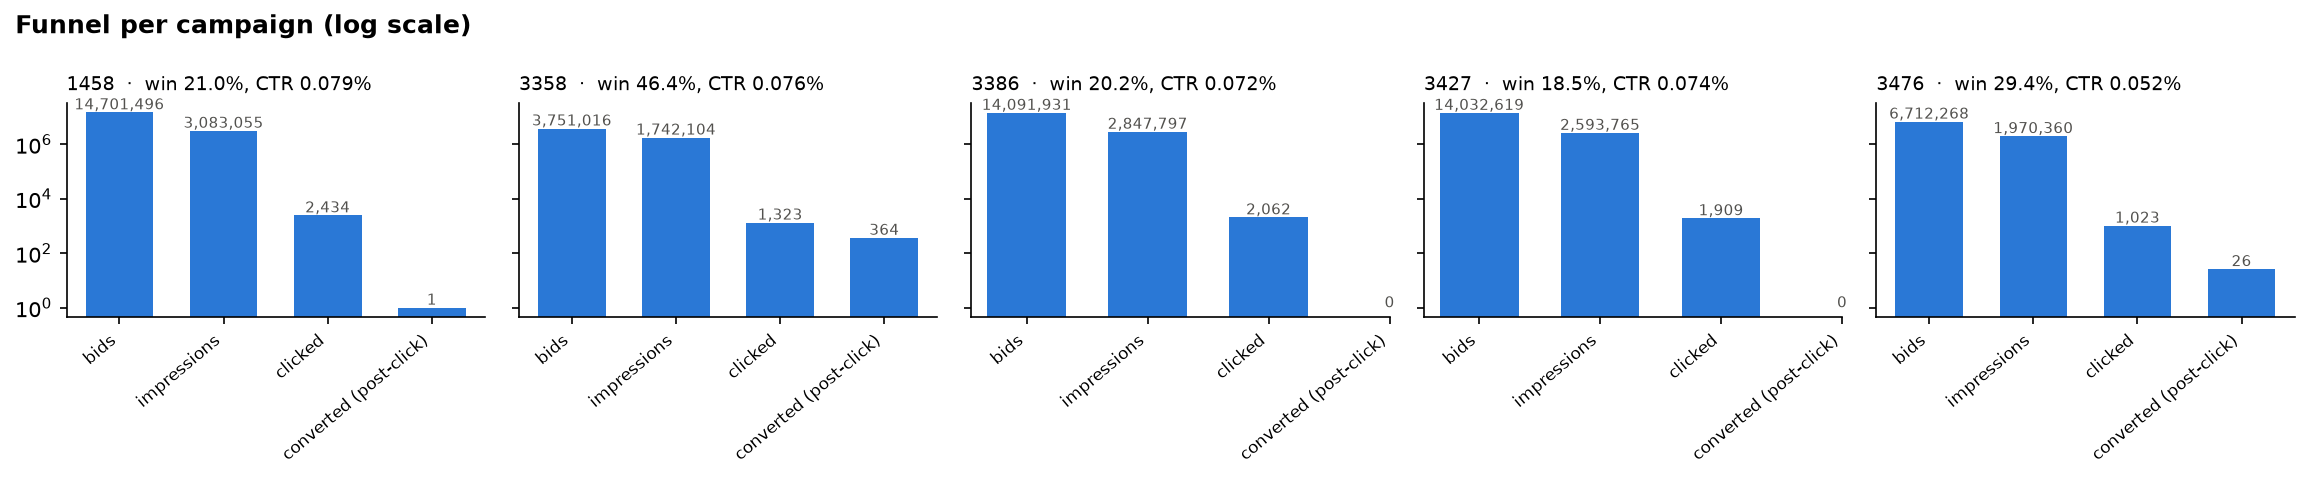

### 2. Browser drives CTR: Safari vs Maxthon

**The number:** Safari 0.479% (95% CI 0.450%–0.509%, +644% vs rest) vs Maxthon 0.036% (-50%); 279 of 481 segment tests survive the multiple-comparison correction

**How confident:** High (q < 0.001)

**What it means for the advertiser:** Shift budget toward Safari and test a lower bid on Maxthon. This is a correlation, so confirm with a controlled bid test.

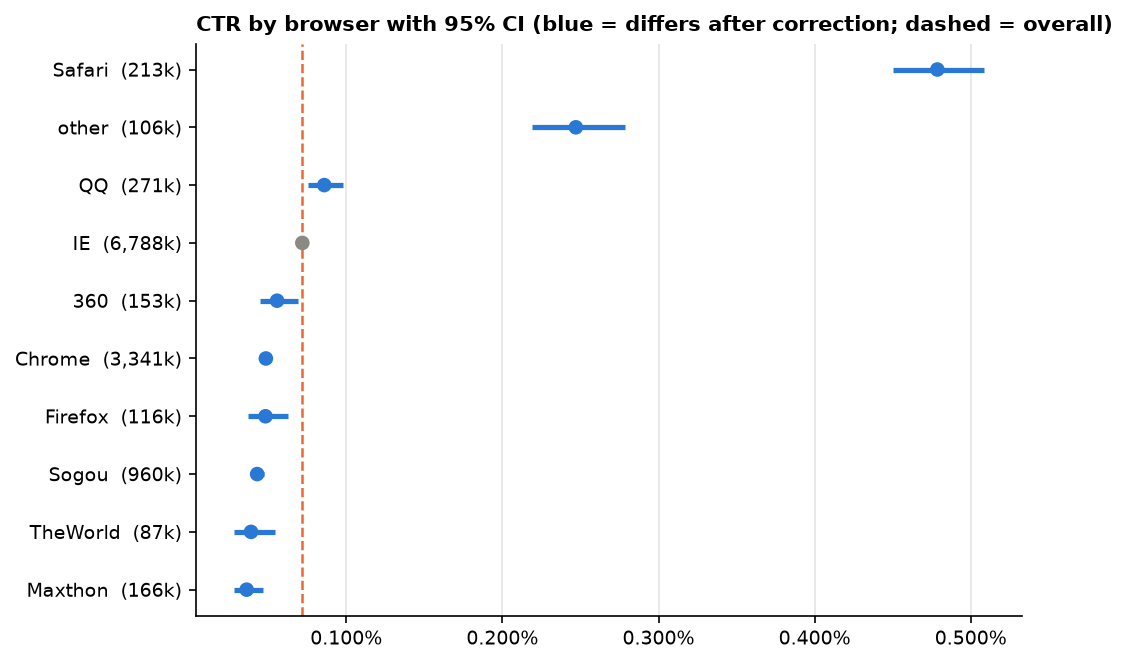

### 3. We pay 29% of what we bid

**The number:** average bid 268 vs average paid 78 (median gap 202); 1458: 23%; 3358: 40%; 3386: 26%; 3427: 34%; 3476: 32%

**How confident:** High (exact over 12,237,087 impressions)

**What it means for the advertiser:** Second-price auctions hide a large overbid. Under first-price auctions the same bids would cost 3.4× as much, so bid shading toward the market price is the main saving.

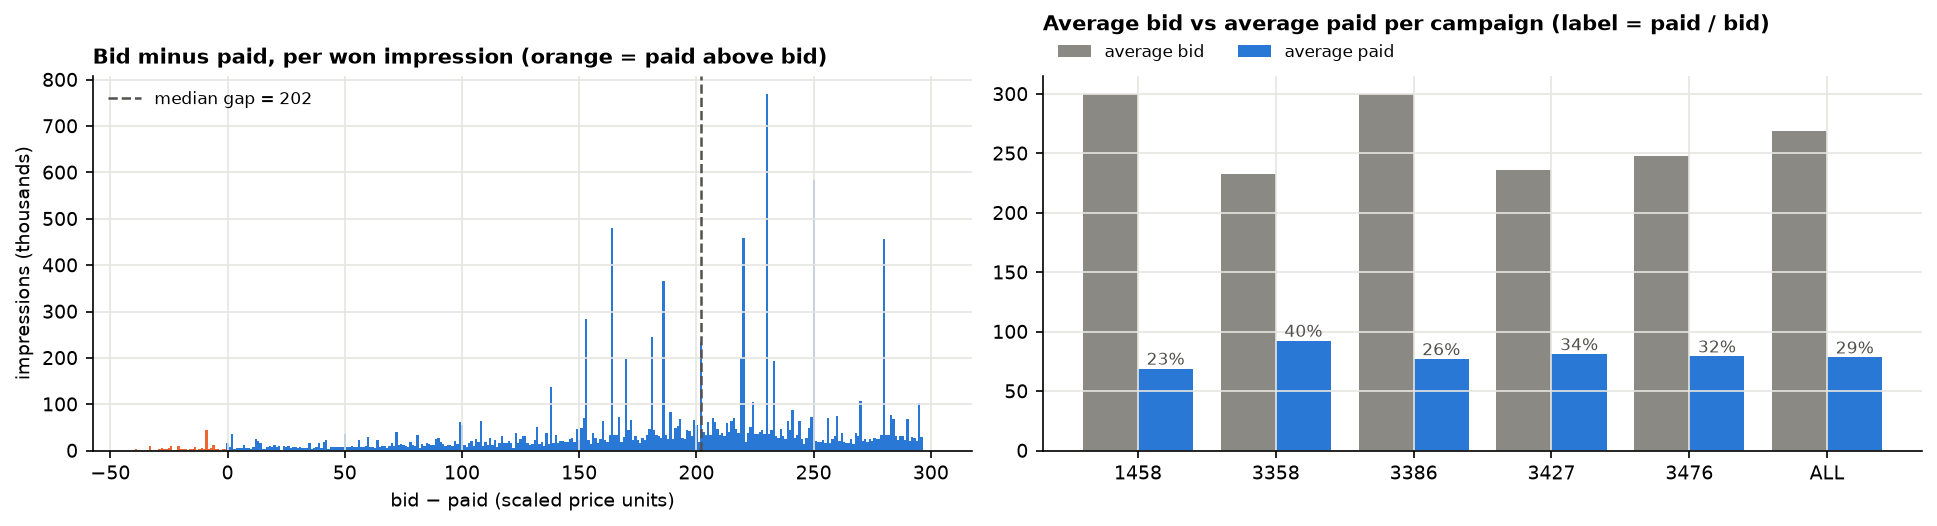

### 4. Simpson's paradox: campaign 1458 vs 3386 flips when split by floor band

**The number:** pooled +9% (p = 0.0038) vs within floor bands -0% (CMH p = 0.94); 15 of 99 comparisons reverse

**How confident:** Low (p = 0.94, not significant)

**What it means for the advertiser:** Pooled numbers can point budget the wrong way here. Always compare within a campaign, or adjust for the mix.

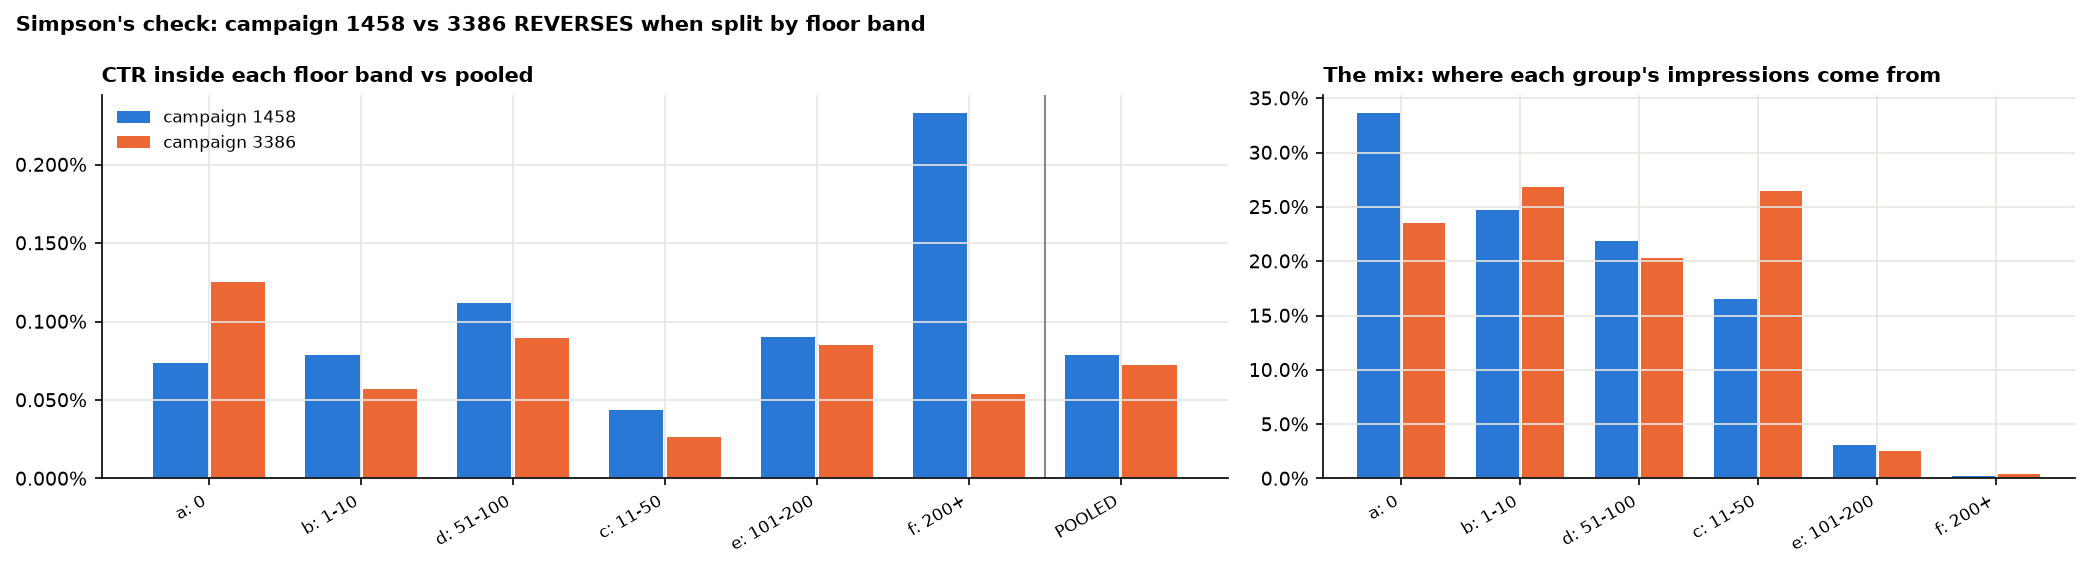

### 5. H2: Evening CTR (18-24h) is higher than daytime CTR (8-18h): supported

**The number:** evening 18-24h 0.082% vs daytime 8-18h 0.064%: +28% (95% CI +22% to +33%), p = 4.28e-25

**How confident:** High (p < 0.001)

**What it means for the advertiser:** A real difference worth acting on with a bid adjustment, after a controlled test.

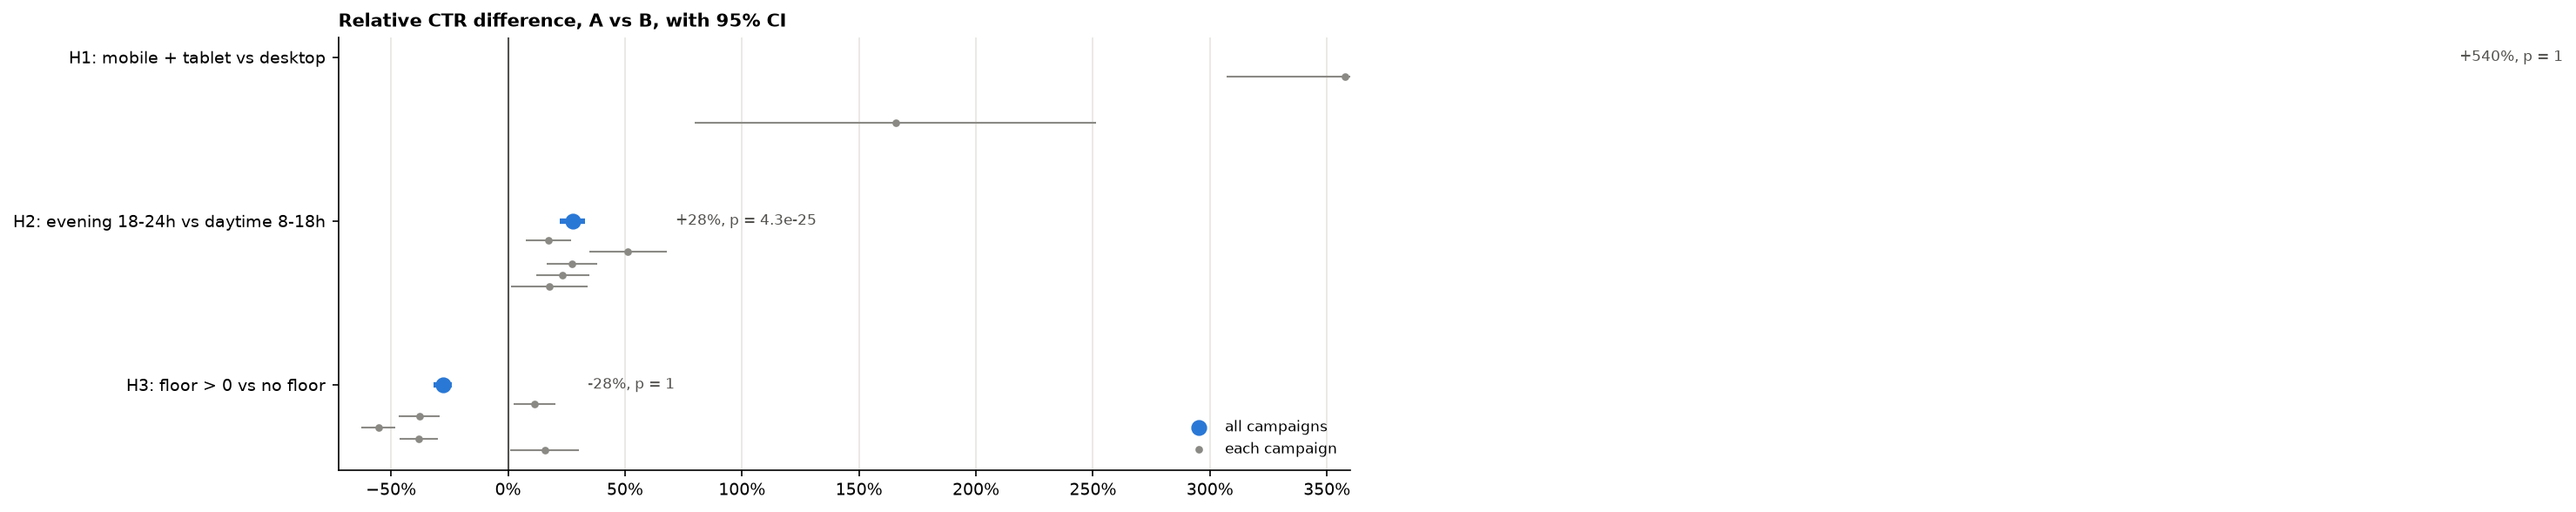

Written: reports/data_story.md and reports/data_story.html (open the HTML in a browser and print it to PDF, landscape, for the one-pager)


In [4]:
# CELL 4: render inline, then write reports/data_story.md and reports/data_story.html
conf_badge = lambda c: c.split(" ")[0]
for k, r in enumerate(STORY.itertuples(), 1):
    display(Markdown(f"### {k}. {r.title}\n\n**The number:** {r.number}\n\n"
                     f"**How confident:** {r.confidence}\n\n**What it means for the advertiser:** {r.meaning}"))
    if r.chart_exists:
        display(Image(filename=str(FIG_DIR / r.chart), width=900))

md_lines = [f"# {TITLE}", "", f"*{SUBTITLE}*" + (f" · {AUTHOR}" if AUTHOR else ""), ""]
for k, r in enumerate(STORY.itertuples(), 1):
    md_lines += [f"## {k}. {r.title}", "", f"**The number:** {r.number}", "",
                 f"![](figures/{r.chart})", "", f"**How confident:** {r.confidence}", "",
                 f"**What it means for the advertiser:** {r.meaning}", ""]
md_lines += ["---", "*Method: rates are ratios of sums. 95% Wilson intervals. Segment tests are corrected for multiple "
             "comparisons (Benjamini–Hochberg). Clicks and conversions are linked to impressions by bid ID, user and "
             "time, and reported on the impression date. Details are in Notebooks 01–09.*"]

def img64(name):
    p = FIG_DIR / name
    return f'<img src="data:image/png;base64,{base64.b64encode(p.read_bytes()).decode()}">' if p.exists() else ""

cards = "".join(
    f"""<section><h2><span>{k}</span>{html.escape(r.title)}</h2>{img64(r.chart)}
        <p class="num">{html.escape(r.number)}</p>
        <p><b>How confident:</b> <em class="c{conf_badge(r.confidence)}">{html.escape(r.confidence)}</em></p>
        <p><b>What it means:</b> {html.escape(r.meaning)}</p></section>"""
    for k, r in enumerate(STORY.itertuples(), 1))
page = f"""<!DOCTYPE html><html><head><meta charset="utf-8"><title>{html.escape(TITLE)}</title><style>
@page {{ size: A4 landscape; margin: 8mm; }}
body {{ font: 10.5px/1.4 -apple-system, "Segoe UI", Roboto, sans-serif; color: #0b0b0b; margin: 14px; }}
h1 {{ font-size: 20px; margin: 0; }} .sub {{ color: #52514e; margin: 2px 0 10px; }}
main {{ display: grid; grid-template-columns: repeat(3, 1fr); gap: 10px; }}
section {{ border: 1px solid #e6e5e0; border-radius: 6px; padding: 8px 10px; break-inside: avoid; }}
h2 {{ font-size: 12.5px; margin: 0 0 6px; }} h2 span {{ display: inline-block; background: #2a78d6; color: #fff;
  border-radius: 50%; width: 18px; height: 18px; text-align: center; line-height: 18px; margin-right: 6px; font-size: 11px; }}
img {{ width: 100%; max-height: 150px; object-fit: contain; }} p {{ margin: 4px 0; }}
.num {{ font-weight: 600; }} em {{ font-style: normal; padding: 0 4px; border-radius: 3px; }}
.cHigh {{ background: #e3f4ec; }} .cMedium {{ background: #fdf3dc; }} .cLow {{ background: #fdeaea; }}
footer {{ color: #52514e; margin-top: 8px; font-size: 9.5px; }}
</style></head><body><h1>{html.escape(TITLE)}</h1>
<div class="sub">{html.escape(SUBTITLE)}{(" · " + html.escape(AUTHOR)) if AUTHOR else ""}</div>
<main>{cards}</main><footer>{html.escape(md_lines[-1].strip('*'))}</footer></body></html>"""

try:
    (PROJECT_ROOT / "reports" / "data_story.md").write_text("\n".join(md_lines), encoding="utf-8")
    (PROJECT_ROOT / "reports" / "data_story.html").write_text(page, encoding="utf-8")
    print("Written: reports/data_story.md and reports/data_story.html "
          "(open the HTML in a browser and print it to PDF, landscape, for the one-pager)")
except OSError as e:
    print("Could not write the story files (disk full?):", e)

## Findings

The five findings above *are* this notebook's findings. Before you submit, check three things:
1. Every number matches the notebook it came from: re-run that notebook if you changed anything.
2. Every "what it means" is a sentence you can defend in your own words.
3. The confidence labels are honest. A *Low* finding can stay in the story, if you say why it is still worth knowing.